Tugas Machine Learning 6

6.1 Persiapan Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

6.2 Import Dataset

In [ ]:
data = load_wine(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

6.3 Preprocessing (Scaling untuk KNN)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


6.4 Training Model

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5, weights="distance")
knn.fit(X_train_scaled, y_train)

nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

6.5 Evaluasi

In [ ]:
acc_knn = accuracy_score(y_test, knn.predict(X_test_scaled))
acc_nb = accuracy_score(y_test, nb.predict(X_test))

print(f"Akurasi KNN (k=5, weighted): {acc_knn:.3f}")
print(f"Akurasi Gaussian Naive Bayes: {acc_nb:.3f}")

Akurasi KNN (k=5, weighted): 0.972
Akurasi Gaussian Naive Bayes: 0.972


6.6 Visualisasi

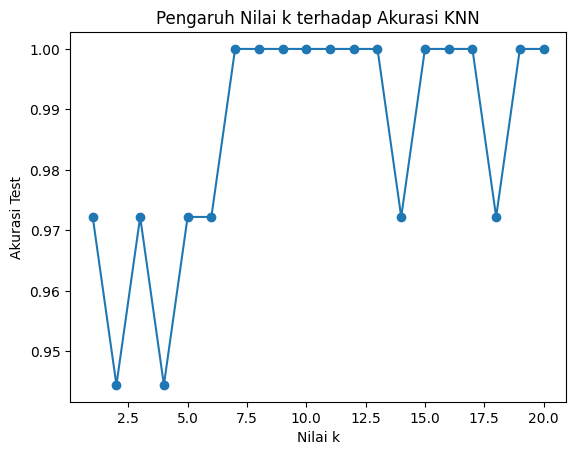

In [ ]:

akurasi_k = []
nilai_k = range(1, 21)

for k in nilai_k:
    model = KNeighborsClassifier(n_neighbors=k).fit(
        X_train_scaled,
        y_train
    )

    akurasi_k.append(
        accuracy_score(
            y_test,
            model.predict(X_test_scaled)
        )
    )

plt.plot(nilai_k, akurasi_k, marker='o')
plt.xlabel("Nilai k")
plt.ylabel("Akurasi Test")
plt.title("Pengaruh Nilai k terhadap Akurasi KNN")
plt.show()

6.7 Praktikum 1

In [ ]:
import time
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=3)

start = time.time()
knn.fit(X_train_scaled, y_train)
waktu_train_knn = time.time() - start

start = time.time()
pred_knn = knn.predict(X_test_scaled)
waktu_prediksi_knn = time.time() - start

akurasi_knn = accuracy_score(y_test, pred_knn)

nb = GaussianNB()

start = time.time()
nb.fit(X_train_scaled, y_train)
waktu_train_nb = time.time() - start

start = time.time()
pred_nb = nb.predict(X_test_scaled)
waktu_prediksi_nb = time.time() - start

akurasi_nb = accuracy_score(y_test, pred_nb)

print("=== HASIL PERBANDINGAN ===")
print("\nKNN")
print("Akurasi :", akurasi_knn)
print("Waktu Training :", waktu_train_knn, "detik")
print("Waktu Prediksi :", waktu_prediksi_knn, "detik")

print("\nGaussian Naive Bayes")
print("Akurasi :", akurasi_nb)
print("Waktu Training :", waktu_train_nb, "detik")
print("Waktu Prediksi :", waktu_prediksi_nb, "detik")

=== HASIL PERBANDINGAN ===

KNN
Akurasi : 0.9824561403508771
Waktu Training : 0.0011839866638183594 detik
Waktu Prediksi : 0.004103183746337891 detik

Gaussian Naive Bayes
Akurasi : 0.9298245614035088
Waktu Training : 0.004149198532104492 detik
Waktu Prediksi : 0.00067901611328125 detik


6.7 Praktikum 2

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

teks = [
    "produk ini sangat bagus",
    "saya sangat puas dengan produk ini",
    "barang berkualitas dan bagus",
    "pelayanannya sangat baik",
    "produk ini mengecewakan",
    "barang sangat buruk",
    "saya tidak puas",
    "kualitas produk jelek"
]

label = [
    "positif",
    "positif",
    "positif",
    "positif",
    "negatif",
    "negatif",
    "negatif",
    "negatif"
]

model = make_pipeline(
    CountVectorizer(),
    MultinomialNB()
)

model.fit(teks, label)

data_baru = [
    "produk sangat bagus",
    "barang ini sangat buruk",
    "saya puas dengan kualitasnya",
    "produk ini mengecewakan"
]

hasil = model.predict(data_baru)

for kalimat, prediksi in zip(data_baru, hasil):
    print(kalimat, "=>", prediksi)

produk sangat bagus => positif
barang ini sangat buruk => negatif
saya puas dengan kualitasnya => positif
produk ini mengecewakan => negatif


6.7 Praktikum

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB


teks = [
    "dapatkan diskon gratis sekarang",
    "rapat tim jam 10 pagi",
    "menangkan hadiah gratis klik disini",
    "laporan keuangan bulan ini",
    "diskon spesial hari ini",
    "jadwal kuliah minggu depan"
]

label = [1, 0, 1, 0, 1, 0]

vectorizer = CountVectorizer()
X_teks = vectorizer.fit_transform(teks)

model = MultinomialNB(alpha=1.0)

model.fit(X_teks, label)

teks_baru = ["diskon gratis hari ini"]

prediksi = model.predict(
    vectorizer.transform(teks_baru)
)

print(
    "Prediksi:",
    "Spam" if prediksi[0] == 1 else "Bukan Spam"
)

Prediksi: Spam
